# Introduction to Qrisp
Qrisp is an open-source project developed across organizations. Main features:
1) Typed quantum variables: Qrisp algorithms are constituted of variables and functions instead of qubits and circuits.
2) Modularity: Automated qubit allocation allows separate modules to recycle qubit resources for each other without intertwining the code.
3) Memory management: QuantumVariables can be uncomputed automatically once they are not needed anymore. (Uncomputation could be a potential seminar presentation!)
4) Many High level implementations of State of the Art Algorithms 
5) high-performance simulator
6) Jax integration: Exert hybrid real-time algorithm control with Catalyst and Jasp. Qrisp’s JAX integration enables seamless hybrid quantum-classical workflows with deep integration into classical compiler infrastructure (LLVM/MLIR). 

This tutorial is inspired by:
https://qrisp.eu/general/tutorial/tutorial.html

Many other tutorials: https://qrisp.eu/general/tutorial/index.html & https://qrisp.eu/reference/Examples/index.html

## First examples

In [19]:
from qrisp import h, cx
from qrisp import QuantumVariable

qv = QuantumVariable(2)
h(qv[0])
cx(qv[0],qv[1])

print(qv.qs)

QuantumCircuit:
---------------
      ┌───┐     
qv.0: ┤ H ├──■──
      └───┘┌─┴─┐
qv.1: ─────┤ X ├
           └───┘
Live QuantumVariables:
----------------------
QuantumVariable qv


In [20]:
qv.get_measurement()

{'00': 0.5, '11': 0.5}

In [21]:
qv.qs.statevector()

sqrt(2)*(|00> + |11>)/2

A cool thing about qrisp is that we can do the hadamard transform as follows without a for loop as we did with Pennylane:

In [22]:
n_qubits=5
qv = QuantumVariable(n_qubits)
h(qv)
print(qv.qs)

QuantumCircuit:
---------------
      ┌───┐
qv.0: ┤ H ├
      ├───┤
qv.1: ┤ H ├
      ├───┤
qv.2: ┤ H ├
      ├───┤
qv.3: ┤ H ├
      ├───┤
qv.4: ┤ H ├
      └───┘
Live QuantumVariables:
----------------------
QuantumVariable qv


## Quantum Floats

Let's look at a special subclass of the QuantumVariable: QuantumFloats!

`msize` indicates the amount of mantissa qubits, which represent the significant digits of a number in a floating-point representation


$$
x_i = i \cdot 2^{e}, \qquad
i \in
\begin{cases}
\{0, 1, \dots, 2^{n}-1\} & \text{unsigned } (n \text{ qubits}) \\
\{-2^{n}, \dots, 2^{n}-1\} & \text{signed } (n+1 \text{ qubits})
\end{cases}
$$

where $n$ is the number of mantissa qubits (`msize`) and $e$ the exponent.

In [23]:
from qrisp import QuantumFloat


a = QuantumFloat(msize=3, exponent=-2, signed=False)
h(a)
print(a)

{0.0: 0.125, 0.25: 0.125, 0.5: 0.125, 0.75: 0.125, 1.0: 0.125, 1.25: 0.125, 1.5: 0.125, 1.75: 0.125}


With `QuantumFloat(n, -n)` the register represents $x = i/2^n \in [0,1)$, i.e. the binary fraction $0.b_1 b_2 \dots b_n$, which is exactly the format of the QPE phase $\varphi$.

In [24]:
precision=3
a = QuantumFloat(precision, -precision)
h(a)
print(a)

{0.0: 0.125, 0.125: 0.125, 0.25: 0.125, 0.375: 0.125, 0.5: 0.125, 0.625: 0.125, 0.75: 0.125, 0.875: 0.125}


In [25]:
for i in range(2**a.size): print(i,i*2**(-precision),a.decoder(i))

0 0.0 0.0
1 0.125 0.125
2 0.25 0.25
3 0.375 0.375
4 0.5 0.5
5 0.625 0.625
6 0.75 0.75
7 0.875 0.875


Let's see some Quantum Arithmetics

In [26]:
a = QuantumFloat(3)
b = QuantumFloat(3)

a[:] = 5
b[:] = 2

c = a + b

In [27]:
compiled=c.qs.compile()

In [28]:
compiled.count_ops()

{'p': 1075,
 'x': 11,
 'h': 96,
 'cx': 1232,
 '2cx': 24,
 'QFT no swap_dg': 3,
 'cz': 3,
 'QFT no swap': 1,
 'z': 1}

In [29]:
compiled.depth(),compiled.t_depth()

(856, 7543)

## QPE example

Let's go straight to QPE, you will see how can be implemented with less effort than pennylane.

We use `with control(res[i])` because allows for controlled unitaries! This statement enters a ControlEnvironment such that every quantum operation inside the indented code block will be controlled on the i-th qubit of res (https://qrisp.eu/reference/Quantum%20Environments/ControlEnvironment.html)


In [30]:
from qrisp import QuantumFloat, control, QFT, h


def QPE(psi, U, precision):
    res = QuantumFloat(precision, -precision)
    h(res)
    for i in range(precision):
        with control(res[i]):
            for _ in range(2**i):
                U(psi)
    return QFT(res, inv=True) # inv=True does what qp.adjoint does in Pennylane

"with control" allows us to run controlled unitaries without explicitly implement them as we did with Pennylane

In [31]:
from qrisp import p, QuantumVariable
import numpy as np


def U(psi):
    phi_1 = 0.5
    phi_2 = 0.125

    p(phi_1 * 2 * np.pi, psi[0])
    p(phi_2 * 2 * np.pi, psi[1])

psi = QuantumVariable(2)

h(psi)

res = QPE(psi, U, 3)

In [32]:
res.qs.statevector()

(|00>*|0.0> + |01>*|0.125> + |10>*|0.5> + |11>*|0.625>)/2

Let's compare with the bult-in result:

In [33]:
from qrisp import QPE


psi = QuantumVariable(2)

h(psi)
res = QPE(psi, U, 3)
res.qs.statevector()

(|00>*|0.0> + |01>*|0.125> + |10>*|0.5> + |11>*|0.625>)/2

## Grover

In the pennylane version, the bitstrings "combos" were written in by hand, but for real problems we don't know the solutions in advance obviously. Let's have an example: we want to find all the $x$ within $[-4,3.5]$ s.t. $x^2=0.25$, assuming that we don't know the solutions

In [36]:
from qrisp import QuantumFloat, auto_uncompute, z
from qrisp.grover import grovers_alg


def sqrt_oracle(x):
    r = x * x
    b = r == 0.25
    z(b)
    b.uncompute()
    r.uncompute()

qf = QuantumFloat(3,-1,signed=True)


qf*qf == 0.25 checks every x and writes the result into one extra qubit: 1 for "right answer", 0 for "wrong answer".
z is the gate that adds a minus sign whenever that qubit is 1. So only the right answers get the minus sign.


In [37]:
grovers_alg(qf, sqrt_oracle)
print(qf)

{0.5: 0.16504330086601735, -0.5: 0.16504330086601735, 0.0: 0.04785095701914038, 1.0: 0.04785095701914038, 1.5: 0.04785095701914038, 2.0: 0.04785095701914038, 2.5: 0.04785095701914038, 3.0: 0.04785095701914038, 3.5: 0.04785095701914038, -4.0: 0.04785095701914038, -3.5: 0.04785095701914038, -3.0: 0.04785095701914038, -2.5: 0.04785095701914038, -2.0: 0.04785095701914038, -1.5: 0.04785095701914038, -1.0: 0.04785095701914038}


let's see what "uncompute" does

In [38]:
sqrt_oracle(qf)
print(qf.qs)

QuantumCircuit:
---------------
                   ┌───┐┌───────────┐                            »
             qf.0: ┤ H ├┤0          ├────────────────────────────»
                   ├───┤│           │                            »
             qf.1: ┤ H ├┤1          ├────────────────────────────»
                   ├───┤│           │                            »
             qf.2: ┤ H ├┤2          ├────────────────────────────»
                   ├───┤│           │                            »
             qf.3: ┤ H ├┤3          ├────────────────────────────»
                   └───┘│           │┌────────┐     ┌───────────┐»
        mul_res.0: ─────┤4          ├┤0       ├─────┤0          ├»
                        │           ││        │     │           │»
        mul_res.1: ─────┤5          ├┤1       ├─────┤1          ├»
                        │           ││        │     │           │»
        mul_res.2: ─────┤6          ├┤2       ├─────┤2          ├»
                        │     

and have a look at the resources:

In [39]:
compiled=qf.qs.compile()
compiled.count_ops(),compiled.depth(),compiled.t_depth()

({'h': 90,
  'cx': 560,
  'p': 608,
  'pt2cx': 96,
  'QFT no swap_dg': 4,
  'x': 54,
  '2cx': 32,
  'reduced_maslov': 32,
  'reduced_maslov_dg': 32,
  'z': 4,
  'QFT no swap': 4,
  '3cx': 3,
  'gphase': 1},
 2338,
 9199)

In [41]:
@auto_uncompute
def sqrt_oracle(x):
    r = x * x
    b = r == 0.25
    z(b)


qf = QuantumFloat(3,-1,signed=True)
grovers_alg(qf, sqrt_oracle)
print(qf)

{0.5: 0.16504330086601735, -0.5: 0.16504330086601735, 0.0: 0.04785095701914038, 1.0: 0.04785095701914038, 1.5: 0.04785095701914038, 2.0: 0.04785095701914038, 2.5: 0.04785095701914038, 3.0: 0.04785095701914038, 3.5: 0.04785095701914038, -4.0: 0.04785095701914038, -3.5: 0.04785095701914038, -3.0: 0.04785095701914038, -2.5: 0.04785095701914038, -2.0: 0.04785095701914038, -1.5: 0.04785095701914038, -1.0: 0.04785095701914038}


# VQE

The heisenberg model Hamiltonian is given by:

$$

        H = J\sum\limits_{(i,j)\in E}(X_iX_j+Y_iY_j+Z_iZ_j)+B\sum\limits_{i\in V}Z_i $$

the coupling constant $J>0$ (antiferromagnetic), and the magnetic field strength $B$.

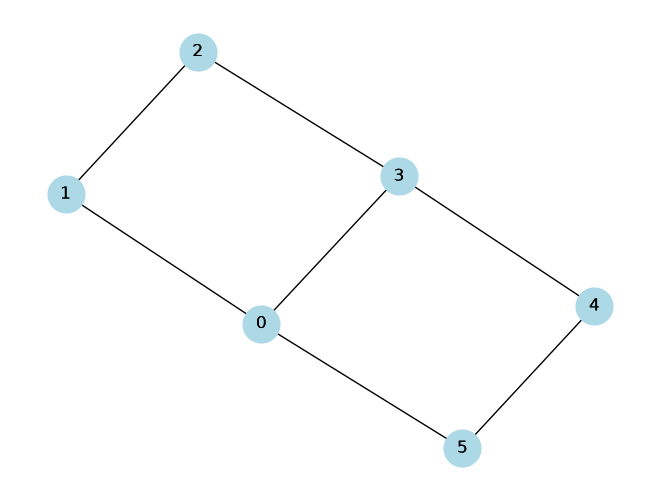

In [45]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a graph
G = nx.Graph()
G.add_edges_from([(0,1),(1,2),(2,3),(0,3),(3,4),(4,5),(5,0)])

# Draw the graph with labels
pos = nx.spring_layout(G)
nx.draw(G, pos, with_labels=True, node_size=700, node_color='lightblue')
nx.draw_networkx_labels(G, pos)
plt.show()

-12.398790938979296                                                             


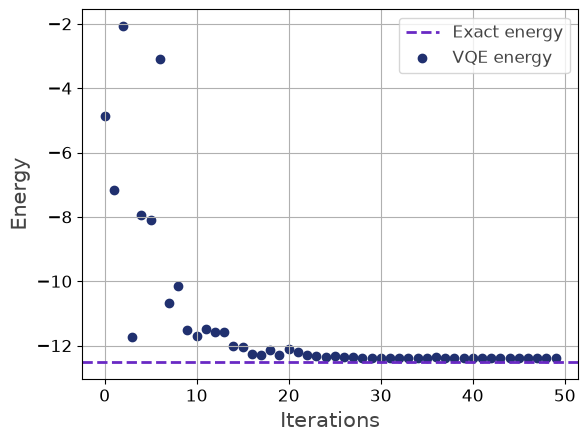

In [49]:
from qrisp import QuantumVariable
from qrisp.vqe.problems.heisenberg import *

vqe = heisenberg_problem(G,J=1,B=1)
vqe.set_callback()
energy = vqe.run(QuantumVariable(G.number_of_nodes()),depth=3,max_iter=50)
print(energy)
vqe.visualize_energy(exact=True)

Play with `init_type`, `init_point`, `optimizer`(from `scipy.minimize`) https://qrisp.eu/reference/Algorithms/vqe/generated/qrisp.vqe.VQEProblem.run.html#qrisp.vqe.VQEProblem.run

Check out also other Hamiltonians they have or if you want, build your own!